# Predictive Model and Statistical Test for Future Energy Demand

This notebook analyses the cleaned household electricity dataset to test whether energy demand differs between weekdays and weekends and to forecast future demand.


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from prophet import Prophet

repo_root = Path.cwd().resolve()
for candidate in [repo_root, *repo_root.parents]:
    data_path = candidate / 'cleaned_data_power_consumption.txt'
    if data_path.exists():
        repo_root = candidate
        break

DATA_PATH = repo_root / 'cleaned_data_power_consumption.txt'
print(f'Dataset path: {DATA_PATH}')
df = pd.read_csv(DATA_PATH, parse_dates=['datetime'])
df.head()


Dataset path: C:\Users\amissetu\Documents\GitHub\final_project\wattwise-energy-analytics\cleaned_data_power_consumption.txt


,datetime,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3
0,2006-12-16 17:00:00,4.2229,0.2290,234.6439,18.1000,0.0,0.5278,16.8611
1,2006-12-16 18:00:00,3.6322,0.0800,234.5802,15.6000,0.0,6.7167,16.8667
2,2006-12-16 19:00:00,3.4002,0.0852,233.2325,14.5033,0.0,1.4333,16.6833
3,2006-12-16 20:00:00,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,16.7833
4,2006-12-16 21:00:00,3.0565,0.0767,237.1587,13.0467,0.0,0.4167,17.2167


In [3]:
df = df.sort_values('datetime').reset_index(drop=True)
df['date'] = df['datetime'].dt.floor('D')
df['hour'] = df['datetime'].dt.hour
df['day_name'] = df['datetime'].dt.day_name()
df['is_weekend'] = df['datetime'].dt.dayofweek >= 5

daily_demand = (
    df.groupby('date', as_index=False)['global_active_power']
      .mean()
      .rename(columns={'global_active_power': 'avg_daily_demand'})
)
daily_demand['day_name'] = daily_demand['date'].dt.day_name()
daily_demand['is_weekend'] = daily_demand['date'].dt.dayofweek >= 5
daily_demand.head()


,date,avg_daily_demand,day_name,is_weekend
0,2006-12-16,3.120300,Saturday,True
1,2006-12-17,2.354492,Sunday,True
2,2006-12-18,1.530429,Monday,False
3,2006-12-19,1.157071,Tuesday,False
4,2006-12-20,1.545654,Wednesday,False


In [4]:
weekday_demand = daily_demand.loc[~daily_demand['is_weekend'], 'avg_daily_demand']
weekend_demand = daily_demand.loc[daily_demand['is_weekend'], 'avg_daily_demand']

t_stat, p_value = stats.ttest_ind(weekday_demand, weekend_demand, equal_var=False)

print(f'Mean weekday demand: {weekday_demand.mean():.4f} kW')
print(f'Mean weekend demand: {weekend_demand.mean():.4f} kW')
print(f'T-statistic: {t_stat:.4f}')
print(f'P-value: {p_value:.10f}')

if p_value < 0.05:
    print('Reject H0: weekday and weekend energy demand are statistically different.')
else:
    print('Fail to reject H0: there is no significant difference between weekday and weekend demand.')


Mean weekday demand: 1.0368 kW
Mean weekend demand: 1.2314 kW
T-statistic: -7.0274
P-value: 0.0000000000
Reject H0: weekday and weekend energy demand are statistically different.


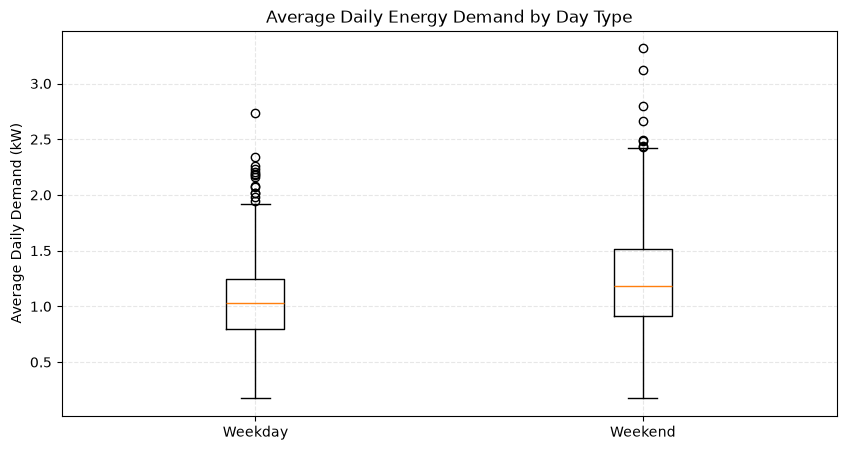

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([weekday_demand, weekend_demand])
ax.set_xticklabels(['Weekday', 'Weekend'])
ax.set_title('Average Daily Energy Demand by Day Type')
ax.set_ylabel('Average Daily Demand (kW)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.show()


In [8]:
forecast_df = daily_demand[['date', 'avg_daily_demand']].rename(columns={'date': 'ds', 'avg_daily_demand': 'y'})
forecast_df['ds'] = pd.to_datetime(forecast_df['ds'])
forecast_df['y'] = pd.to_numeric(forecast_df['y'], errors='coerce')

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
)
model.fit(forecast_df)

future = model.make_future_dataframe(periods=30)
forecast = model.predict(future)
forecast['ds'] = pd.to_datetime(forecast['ds'])
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(10)


02:08:39 - cmdstanpy - INFO - Chain [1] start processing
02:08:40 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
1453,2010-12-17,1.410578,1.030212,1.795262
1454,2010-12-18,1.619569,1.204101,1.961833
1455,2010-12-19,1.601889,1.235260,1.982937
1456,2010-12-20,1.391319,0.999542,1.760412
1457,2010-12-21,1.472312,1.120354,1.838086
1458,2010-12-22,1.486996,1.111097,1.868347
1459,2010-12-23,1.394112,1.005863,1.771955
1460,2010-12-24,1.454062,1.106336,1.833654
1461,2010-12-25,1.656365,1.283141,2.022516
1462,2010-12-26,1.630858,1.268815,2.000615


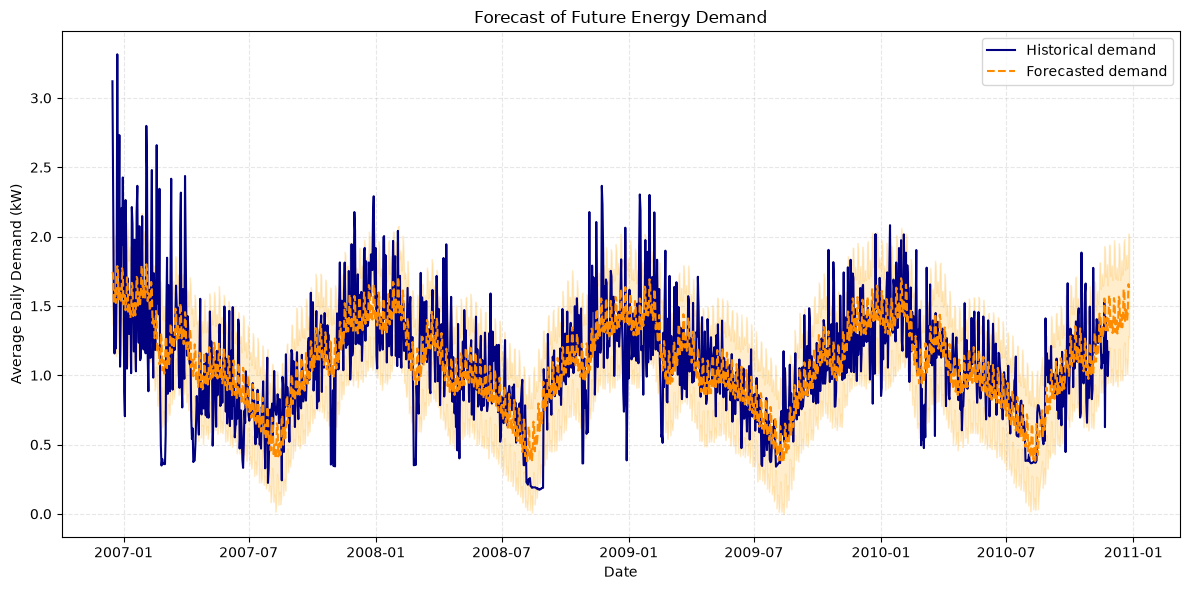

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(forecast_df['ds'], forecast_df['y'], label='Historical demand', color='navy')
ax.plot(forecast['ds'], forecast['yhat'], label='Forecasted demand', color='darkorange', linestyle='--')
ax.fill_between(forecast['ds'], forecast['yhat_lower'], forecast['yhat_upper'], color='orange', alpha=0.2)
ax.set_title('Forecast of Future Energy Demand')
ax.set_xlabel('Date')
ax.set_ylabel('Average Daily Demand (kW)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)
fig.tight_layout()
plt.show()


## Interpretation

- If the p-value is below 0.05, the difference between weekday and weekend energy demand is statistically significant.
- The Prophet model forecasts future demand based on historical patterns and seasonality.
- These results can help with energy planning, peak management, and demand reduction decisions.
